<a href="https://colab.research.google.com/github/Katysssha/predictive-analysis/blob/main/practice3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practice #3. "Dynamic predictive models"

In [1]:
!git clone https://github.com/klymya/ts_cource_practice.git
%cd ts_cource_practice/notebooks

Cloning into 'ts_cource_practice'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 53 (delta 21), reused 45 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 295.42 KiB | 2.64 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/ts_cource_practice/notebooks


Stationarity, differencing, autocorrelation, AR forecasting and SSA.

Fill in the cells tagged `graded`, keeping every name and signature exactly as
given — they are graded automatically.

**Two series below, not interchangeable:**
- `demo_stationary`, `demo_random_walk` — short seeded synthetic series, used
  only to show what each test responds to.
- `series` — the real Melbourne temperatures. "Your series" always means this.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import acf, adfuller, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())
RANDOM_SEED = 42

## 0. Data

In [3]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    df = pd.read_csv(path, usecols=[time_col, value_col])
    df = df.rename(columns={time_col: 'ds', value_col: 'y'})
    df['ds'] = pd.to_datetime(df['ds'])
    df = df.dropna()
    df = df.set_index('ds')
    return df['y'].astype(float)

3650 points, 1981-01-01 to 1990-12-31


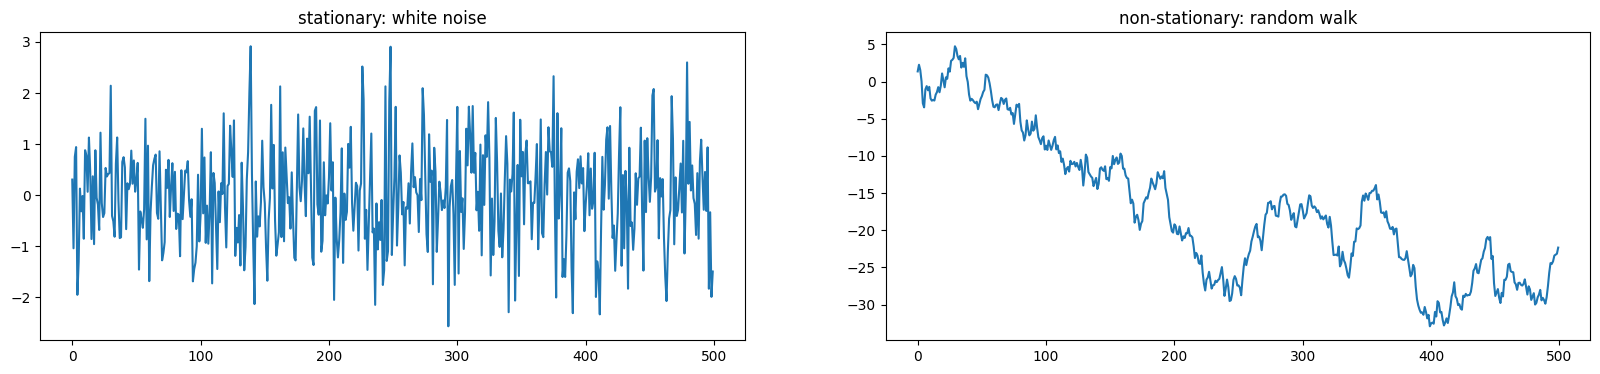

In [4]:
series = load_series(DATA_DIR / "daily-min-temperatures.csv", "Date", "Temp")
print(f"{len(series)} points, {series.index.min():%Y-%m-%d} to {series.index.max():%Y-%m-%d}")

rng = np.random.default_rng(RANDOM_SEED)
demo_stationary = pd.Series(rng.normal(0, 1, 500))
demo_random_walk = pd.Series(rng.normal(0, 1, 500).cumsum())

fig, axes = plt.subplots(1, 2, figsize=(20, 4))
demo_stationary.plot(ax=axes[0], title="stationary: white noise")
demo_random_walk.plot(ax=axes[1], title="non-stationary: random walk");

## 1. Stationarity and the Dickey-Fuller test

A series is stationary when its mean, variance and autocovariance do not depend
on *when* you look. AR, MA and ARMA all assume it.

ADF's null is **"there is a unit root"** — non-stationary. So a **small**
p-value rejects the null and means *stationary*. Inverting this is the most
common error in this practice.

In [7]:
def adf_test(series, significance=0.05):
    """Augmented Dickey-Fuller test."""
    res = adfuller(series)
    return {
        "statistic": res[0],
        "p_value": res[1],
        "used_lag": res[2],
        "n_obs": res[3],
        "critical_values": res[4],
        "is_stationary": res[1] < significance
    }

In [8]:
for name, candidate in (("white noise", demo_stationary),
                        ("random walk", demo_random_walk),
                        ("temperatures", series)):
    result = adf_test(candidate)
    verdict = "stationary" if result["is_stationary"] else "NON-stationary"
    print(f"{name:>14}: p = {result['p_value']:.2e}  ->  {verdict}")

/tmp/ipykernel_5160/3078970485.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)
/tmp/ipykernel_5160/3078970485.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)


   white noise: p = 0.00e+00  ->  stationary
   random walk: p = 2.67e-01  ->  NON-stationary
  temperatures: p = 2.47e-04  ->  stationary


/tmp/ipykernel_5160/3078970485.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)


### 1.1 Differencing

Replacing `y[t]` with `y[t] - y[t-1]` removes a unit root. One difference
usually kills a linear trend, two handle a quadratic one. Over-differencing adds
noise, so stop as soon as the test agrees.

Practice 4 reuses this: the number of differences is the `d` in ARIMA(p, d, q).

In [9]:
def difference(series, periods=1):
    """Difference, then drop the NaNs the shift introduces."""
    return series.diff(periods=periods).dropna()

def make_stationary(series, max_diff=2, significance=0.05):
    """Difference until ADF calls the series stationary."""
    curr_series = series.copy()
    for n_diff in range(max_diff + 1):
        if adf_test(curr_series, significance)["is_stationary"]:
            return curr_series, n_diff
        if n_diff < max_diff:
            curr_series = difference(curr_series, 1)
    return curr_series, max_diff

In [10]:
walk_stationary, n_diffs = make_stationary(demo_random_walk)
print(f"random walk needed {n_diffs} difference(s); "
      f"p-value now {adf_test(walk_stationary)['p_value']:.2e}")

series_stationary, series_diffs = make_stationary(series)
print(f"temperatures needed {series_diffs} difference(s)")

/tmp/ipykernel_5160/3078970485.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)
/tmp/ipykernel_5160/3078970485.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)
/tmp/ipykernel_5160/3078970485.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0

random walk needed 1 difference(s); p-value now 0.00e+00
temperatures needed 0 difference(s)


/tmp/ipykernel_5160/3078970485.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)


**Question.** The series has a strong yearly cycle, yet ADF calls it
stationary with zero differences. Is a seasonal series stationary? What is ADF
sensitive to, and what does it ignore?

Answer: A seasonal series is technically non-stationary because its mean depends on the time of year. However, the ADF test only checks for a unit root (a stochastic trend like a random walk), not for deterministic seasonality. Since the temperature oscillates around a constant long-term mean and doesn't drift away indefinitely, ADF finds no unit root and labels it "stationary", completely ignoring the repeating seasonal pattern.

## 2. Autocorrelation analysis

- **ACF** at lag k — correlation of `y[t]` with `y[t-k]`, everything in between
  included.
- **PACF** at lag k — the same, with the intermediate lags partialled out.

Rule of thumb for Practice 4: PACF cuts off after lag p => AR(p); ACF cuts off
after lag q => MA(q).

In [11]:
def acf_values(series, nlags):
    """Autocorrelations, lags 0..nlags, as a 1-D numpy array."""
    return acf(series, nlags=nlags)

def pacf_values(series, nlags):
    """Partial autocorrelations, lags 0..nlags, as a 1-D numpy array."""
    return pacf(series, nlags=nlags)

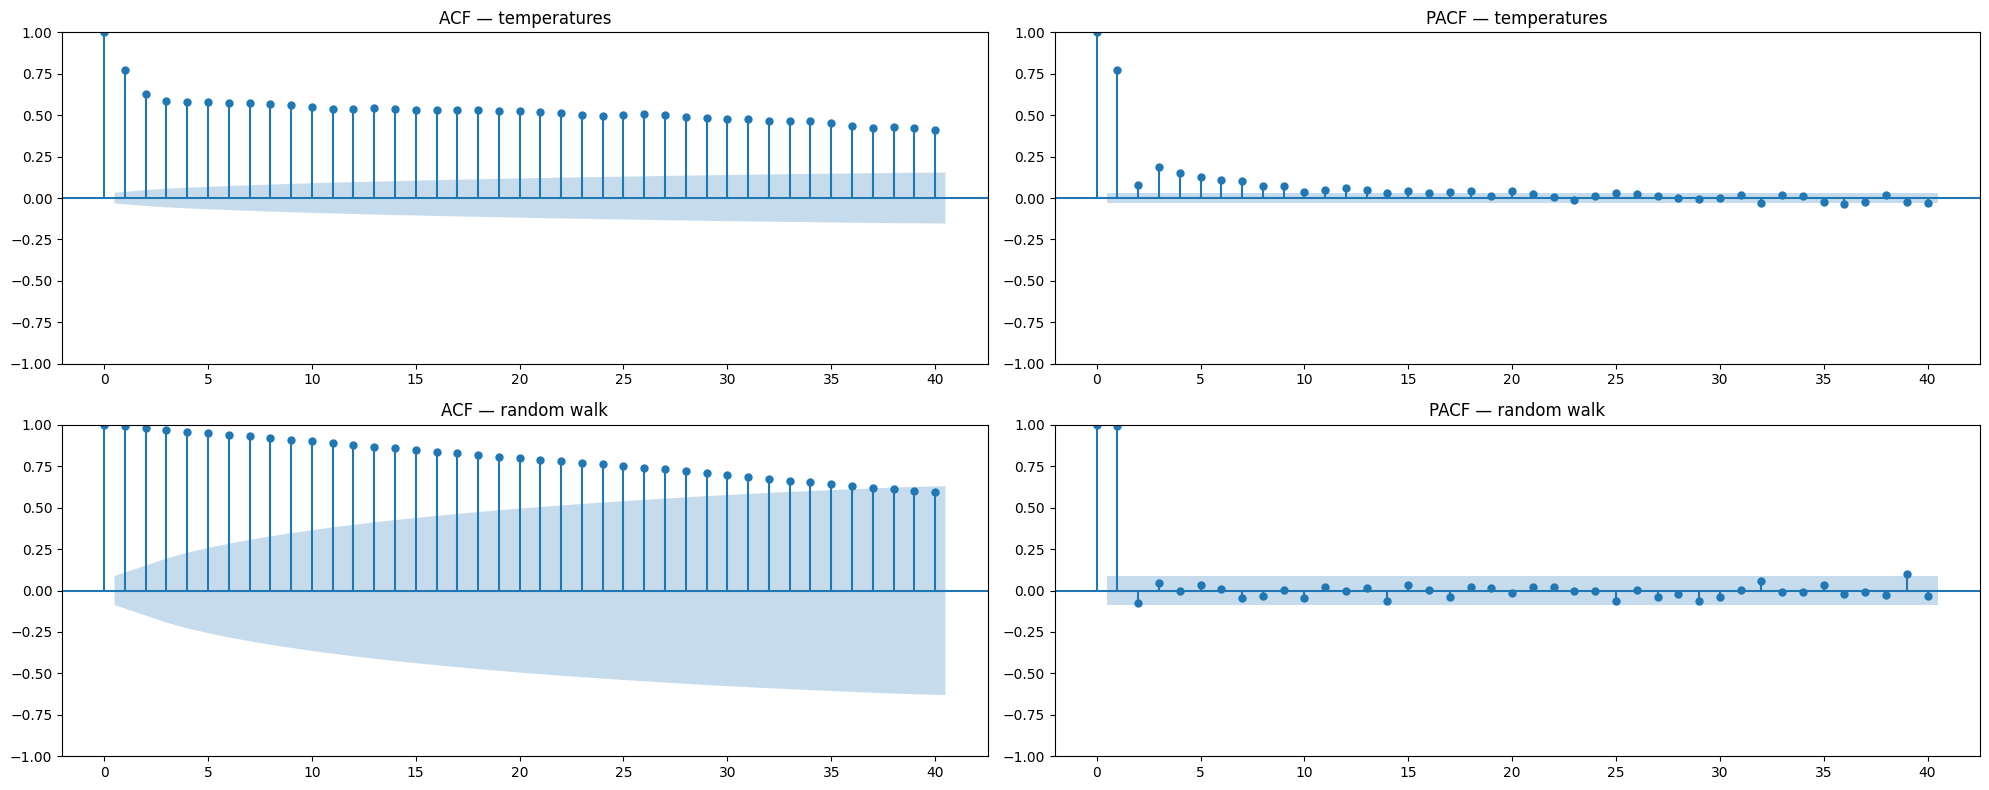

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(20, 8))
plot_acf(series, lags=40, ax=axes[0, 0], title="ACF — temperatures")
plot_pacf(series, lags=40, ax=axes[0, 1], title="PACF — temperatures")
plot_acf(demo_random_walk, lags=40, ax=axes[1, 0], title="ACF — random walk")
plot_pacf(demo_random_walk, lags=40, ax=axes[1, 1], title="PACF — random walk")
plt.tight_layout();

In [13]:
pacf_temps = pacf_values(series, 10)
print("PACF lags 1..10:", np.round(pacf_temps[1:], 3))
print("\nlags whose |PACF| exceeds the 95% band:",
      [lag for lag in range(1, 11)
       if abs(pacf_temps[lag]) > 1.96 / np.sqrt(len(series))])

PACF lags 1..10: [0.774 0.077 0.189 0.152 0.13  0.11  0.103 0.075 0.07  0.036]

lags whose |PACF| exceeds the 95% band: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


**Question.** The random walk's ACF decays slowly while its PACF cuts
off after lag 1. What does that pattern mean, and how does one difference change
it?

Answer: A slowly decaying ACF with a PACF that cuts off at lag 1 indicates that the current value is strongly dependent entirely on the immediate previous value, which is the signature of a random walk. Differencing the series once extracts the pure noise component, turning it into stationary white noise, making both the ACF and PACF drop to near zero for all lags $>0$

## 3. Forecasting with an AR model

AR(p) regresses `y[t]` on its own previous p values. Pick p from the PACF plot
above, then forecast the held-out year.

In [16]:
def ar_forecast(train, index, lags):
    """Fit AutoReg(lags) on `train`, forecast over `index`."""
    model = AutoReg(train.values, lags=lags)
    fit = model.fit()
    return pd.Series(fit.forecast(steps=len(index)), index=index)

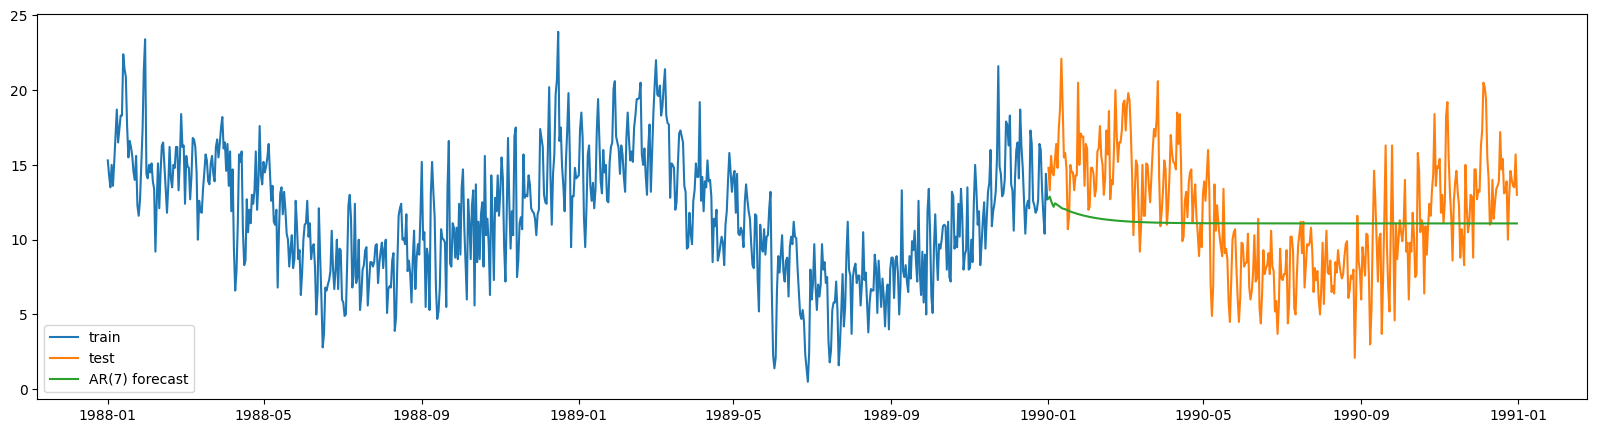

AR(7) RMSE: 3.7902


In [17]:
train, test = series.iloc[:-365], series.iloc[-365:]
forecast = ar_forecast(train, test.index, lags=7)

plt.figure(figsize=(20, 5))
plt.plot(train.iloc[-730:], label="train")
plt.plot(test, label="test")
plt.plot(forecast, label="AR(7) forecast")
plt.legend()
plt.show()

error = np.sqrt(np.mean((test.to_numpy() - forecast.to_numpy()) ** 2))
print(f"AR(7) RMSE: {error:.4f}")

**Question.** The forecast flattens after a few steps. Why does a pure
AR model converge to the series mean, and what does that mean for a 365-day
horizon?

Answer: An AR model is structurally designed for stationary data, meaning it assumes the series will eventually revert to its historical mean. With each future step, the impact of the final observed lags decays to zero, leaving only the constant (mean) term. For a 365-day horizon, an AR model is unable to capture deterministic annual seasonality and becomes effectively useless, converging simply to a flat line at the annual average.

## 4. Singular Spectrum Analysis (SSA)

Decomposes a series without assuming a model. Three steps:

1. **Embed** — stack lagged windows of length L into a trajectory matrix.
2. **Decompose** — SVD; each singular triple gives one elementary matrix.
3. **Reconstruct** — sum the elementary matrices you want, then average the
   anti-diagonals back into a series (*diagonal averaging*).

The SVD is exact, so summing **all** components must return the original series.
The tests check that, and so should you while debugging.

In [19]:
def trajectory_matrix(series, window_length):
    """Hankel matrix of lagged windows — step 1 of SSA.

    N points, window L -> an (L, K) matrix, K = N - L + 1, column k being
    series[k : k + L].
    """
    values = np.asarray(series, dtype=float)
    n_points = len(values)
    n_columns = n_points - window_length + 1
    if n_columns < 1:
        raise ValueError("window_length must not exceed len(series)")
    return np.column_stack([values[k:k + window_length] for k in range(n_columns)])

In [20]:
def diagonal_average(matrix):
    """Average the anti-diagonals of an (L, K) matrix back into a series."""
    flipped = np.fliplr(matrix)
    L, K = matrix.shape
    return np.array([flipped.diagonal(offset=K - 1 - i).mean() for i in range(L + K - 1)])

def ssa_reconstruct(series, window_length, indices):
    """Reconstruct a series from the SSA components in `indices`."""
    X = trajectory_matrix(series, window_length)
    U, S, VT = np.linalg.svd(X, full_matrices=False)

    X_rec = np.zeros_like(X, dtype=float)
    for i in indices:
        X_rec += S[i] * np.outer(U[:, i], VT[i, :])

    return pd.Series(diagonal_average(X_rec), index=series.index)

max |original - full reconstruction| = 2.63e-13


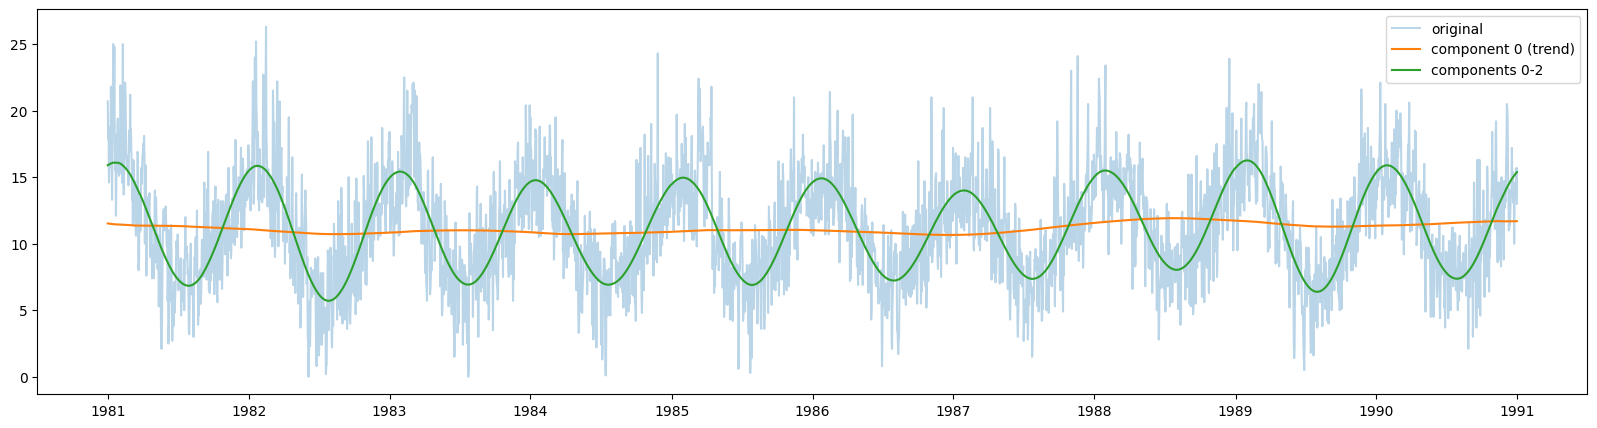

In [21]:
window = 365
full = ssa_reconstruct(series, window, range(min(window, len(series) - window + 1)))
print(f"max |original - full reconstruction| = {float((series - full).abs().max()):.2e}")

trend_component = ssa_reconstruct(series, window, [0])
seasonal_component = ssa_reconstruct(series, window, [1, 2])

plt.figure(figsize=(20, 5))
plt.plot(series, alpha=0.3, label="original")
plt.plot(trend_component, label="component 0 (trend)")
plt.plot(trend_component + seasonal_component, label="components 0-2")
plt.legend();

Pick L between N/4 and N/3, plot the singular values, and decide how
many components carry signal rather than noise.

**Question.** Components 1 and 2 usually arrive as a pair with nearly equal
singular values. What structure produces a *pair*, and why can one component
alone not represent it?

Answer: A cyclic or periodic structure (like an annual sine wave) produces a pair. A single component alone represents a fixed shape and phase. To represent a wave that shifts over time and to allow for arbitrary phase alignments across the windows, the SVD requires two orthogonal components (functioning like sine and cosine) that combine in varying proportions.

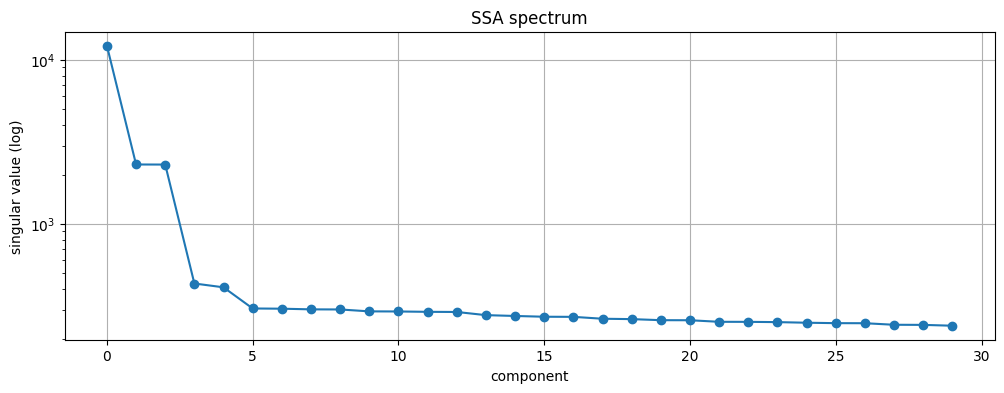

In [22]:
matrix = trajectory_matrix(series, window)
singular_values = np.linalg.svd(matrix, compute_uv=False)

plt.figure(figsize=(12, 4))
plt.semilogy(singular_values[:30], "o-")
plt.xlabel("component")
plt.ylabel("singular value (log)")
plt.title("SSA spectrum")
plt.grid(True);